# 01_train_eval.ipynb

## Setup

In [1]:
# Mount colab
import os
import sys
from pathlib import Path

if True:
    if not os.path.exists('/content/drive'):
        from google.colab import drive
        drive.mount('/content/drive')

# Paths
PROJECT_ROOT: Path = Path(f"/content/drive/MyDrive/python/projects/nlp_projects/text_classification/climate_skepticism")
os.chdir(PROJECT_ROOT)

# Add the PROJECT_ROOT directory to the Python path to import modules
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f"ℹ️ Current Python version: {sys.version}")

ℹ️ Current Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [ ]:
# Install reqs
if True:
    %pip install -r "requirements/train_eval.txt"

INFO: pip is looking at multiple versions of gradio to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 46.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 87.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.2/73.2 kB 8.6 MB/s eta 0:00:00
  Attempting uninstall: starlette
    Found existing installation: starlette 0.52.1
    Uninstalling starlette-0.52.1:
      Successfully uninstalled starlette-0.52.1
  Attempting uninstall: gradio-client
    Found existing installation: gradio_client 1.14.0
    Uninstalling gradio_client-1.14.0:
      Successfully uninstalled gradio_client-1.14.0
  Attempting uninstall: gradio
    Found existing installation: gradio 5.50.0
    Uninstalling gradio

In [ ]:
# -- project imports --
from src.config import load_configs
from src.utils.generic import set_seed, dynamic_module_reloader
from src.utils.train import WeightedLossTrainer, check_weight_strategy

import torch
from typing import Literal
import pandas as pd
import numpy as np
from pprint import pprint
from matplotlib import pyplot as plt
import seaborn as sns
from datasets import load_dataset, DatasetDict, ClassLabel
import trackio
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoConfig,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)
from peft import LoraConfig, get_peft_model, TaskType
import evaluate

# Set seaborn style
sns.set_style('darkgrid')

# Reload modules for interactive development
MODULES_TO_RELOAD: list[str] = [
    "src.config",
    "src.utils.generic",
    "src.utils.train",
]

In [ ]:
# Initialize configs
dynamic_module_reloader(modules=MODULES_TO_RELOAD, verbose=1)
config = load_configs()
set_seed(config.env.seed)

# Set constants
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAKE_BINARY: bool = False
PUSH_TO_HUB: bool = True
SAVE_LOCAL: bool = False
SMOKE_TEST: bool = False
VALIDATION_ONLY: bool = False
WEIGHT_STRATEGY: Literal["balanced", "smoothed", "none"] = "none"

print(f"ℹ️ Using device: {DEVICE}")
print(f"ℹ️ Push to Hugging Face Hub: {PUSH_TO_HUB}")
print(f"ℹ️ Save local copy of the model: {SAVE_LOCAL}")
print(f"ℹ️ Smoke test: {SMOKE_TEST}")
print(f"ℹ️ Validation only: {VALIDATION_ONLY}")
print(f"ℹ️ Weight strategy: {WEIGHT_STRATEGY}")

if MAKE_BINARY:
    FINETUNED_MODEL_NAME: str = config.model.finetuned_model_binary + "-" + config.model.version
    print(f"ℹ️ Making binary classification model: {FINETUNED_MODEL_NAME}")
else:
    FINETUNED_MODEL_NAME: str = config.model.finetuned_model_multiclass + "-" + config.model.version
    print(f"ℹ️ Making multiclass classification model: {FINETUNED_MODEL_NAME}")

# Change configs in notebook
if SMOKE_TEST:
    FINETUNED_MODEL_NAME: str = f"{FINETUNED_MODEL_NAME}-smoke_test"

pprint(config.to_dict())

Reloaded: src.config
Reloaded: src.utils.generic
Reloaded: src.utils.train
⚠️ Colab secrets not found or an error occurred: Requesting secret HF_WRITE_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.
✅ Loaded .env file for local development.
✅ Seed set: 42
ℹ️ Using device: cuda
ℹ️ Inference only: False
ℹ️ Push to Hugging Face Hub: True
ℹ️ Save local copy of the model: False
ℹ️ Smoke test: False
ℹ️ Weight strategy: none
ℹ️ Making multiclass classification model: climate_sceptic-frugalai-roberta-large-multiclass-LoRA-v1.1
{'data': {'dataset_repo': 'QuotaClimat/frugalaichallenge-text-train'},
 'env': {'is_kaggle': False, 'requires_keys': True, 'seed': 42},
 'model': {'base_model': 'roberta-large',
           'finetuned_model_binary': 'climate_sceptic-frugalai-roberta-large-binary-LoRA',
           'finetuned_model_multiclass': 'climate_sceptic-frugalai-roberta-large-multiclass-LoRA',
           'version': 'v1.1'},
 'tracking': {'project': 'ClimateSkepticism',
 

---
## Data

[Frugal AI Challenge](https://huggingface.co/datasets/QuotaClimat/frugalaichallenge-text-train) dataset

In [8]:
# Download the dataset
raw_datasets = load_dataset(config.data.dataset_repo)
print(raw_datasets)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['quote', 'label', 'source', 'url', 'language', 'subsource', 'id', '__index_level_0__'],
        num_rows: 4872
    })
    test: Dataset({
        features: ['quote', 'label', 'source', 'url', 'language', 'subsource', 'id', '__index_level_0__'],
        num_rows: 1219
    })
})


In [9]:
# Get number of labels for the model config
labels = sorted(raw_datasets["train"].unique("label"))
num_labels = len(labels)
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for i, label in enumerate(labels)}

print(f"Number of labels: {num_labels}")
print(f"Label to ID mapping: {label2id}")
print(f"ID to Label mapping: {id2label}")

Number of labels: 8
Label to ID mapping: {'0_not_relevant': 0, '1_not_happening': 1, '2_not_human': 2, '3_not_bad': 3, '4_solutions_harmful_unnecessary': 4, '5_science_unreliable': 5, '6_proponents_biased': 6, '7_fossil_fuels_needed': 7}
ID to Label mapping: {0: '0_not_relevant', 1: '1_not_happening', 2: '2_not_human', 3: '3_not_bad', 4: '4_solutions_harmful_unnecessary', 5: '5_science_unreliable', 6: '6_proponents_biased', 7: '7_fossil_fuels_needed'}


In [10]:
# Rename text column
raw_datasets = raw_datasets.rename_column("quote", "text")

# Cast 'label' column to ClassLabel type for stratification
raw_datasets = raw_datasets.cast_column(
    "label",
    ClassLabel(num_classes=len(id2label), names=list(id2label.values()))
)

# Create validation split
valid_test_split = raw_datasets["test"].train_test_split(
    test_size=0.5,stratify_by_column="label",
    seed=config.env.seed
)
raw_datasets["valid"] = valid_test_split["train"]
raw_datasets["test"] = valid_test_split["test"]
print(raw_datasets)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'source', 'url', 'language', 'subsource', 'id', '__index_level_0__'],
        num_rows: 4872
    })
    test: Dataset({
        features: ['text', 'label', 'source', 'url', 'language', 'subsource', 'id', '__index_level_0__'],
        num_rows: 610
    })
    valid: Dataset({
        features: ['text', 'label', 'source', 'url', 'language', 'subsource', 'id', '__index_level_0__'],
        num_rows: 609
    })
})


In [11]:
# Define the filtering function
def filter_labels(example):
    labels_to_drop = ['7_fossil_fuels_needed']
    return example["label"] not in labels_to_drop

# Collapse labels -> binary
def collapse_labels(example):
    label_zero = '0_not_relevant'
    if example["label"] == label_zero:
        example["label"] = 0
    else:
        example["label"] = 1
    return example

# Processed dataset
if False:
    raw_datasets = raw_datasets.filter(filter_labels)
if MAKE_BINARY:
    raw_datasets = raw_datasets.map(collapse_labels)

<Axes: ylabel='label'>

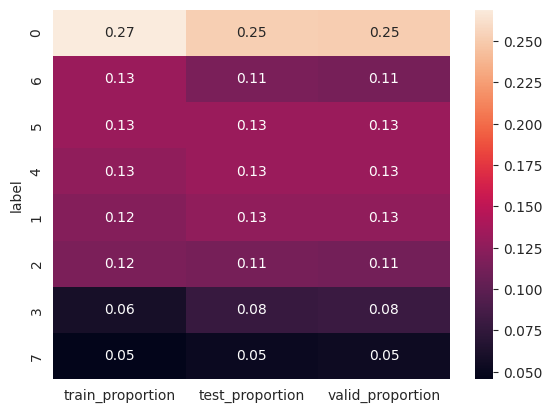

In [12]:
# Check label proportions in sets
proportion_df = pd.DataFrame()

for key in raw_datasets.keys():
    proportion_df = pd.concat([
        proportion_df,
        raw_datasets[key]
            .to_pandas()['label']
            .value_counts(normalize=True)
            .to_frame()
            .rename(columns={'proportion': f'{key}_proportion'})
    ], axis=1)

sns.heatmap(proportion_df, annot=True, fmt=".2f")

## Model fine-tuning

### Training setup

In [13]:
# Initialize tokenizer and data collator
tokenizer = AutoTokenizer.from_pretrained(config.model.base_model)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
def tokenize_function(example):
    return tokenizer(
        example["text"],
        truncation=True,
        padding=not 'data_collator' in globals(),
        )

# Tokenize dataset
tokenized_dataset = raw_datasets.map(tokenize_function, batched=True)

# Map string labels to integer IDs
# If it's not a ClassLabel (meaning it's likely still string-based)
if not type(raw_datasets['train'].features['label']) == ClassLabel:
    tokenized_dataset = tokenized_dataset.map(lambda example: {'label': label2id[example['label']]}, batched=False)

Map:   0%|          | 0/610 [00:00<?, ? examples/s]

In [14]:
if SMOKE_TEST:
    print("ℹ️ Creating a smaller dataset for smoke testing")
    sampled_dataset = DatasetDict()
    for split_name, dataset in tokenized_dataset.items():
        sampled_dataset[split_name] = (
            dataset
            .shuffle(seed=config.env.seed)
            .select(range(100))
        )

    print(sampled_dataset)

--- IMBALANCE ANALYSIS ---
Majority class count: 1311
Minority class count: 222
Imbalance ratio:      5.91:1

--- RECOMMENDATION ---
Use NORMAL (balanced) weights.
Reason: Imbalance is mild (under 10.0:1).
Model will safely handle raw scaling.
Unsmoothed class weights range: 0.46 → 2.74
Smoothed class weights range: 1.31 → 2.14


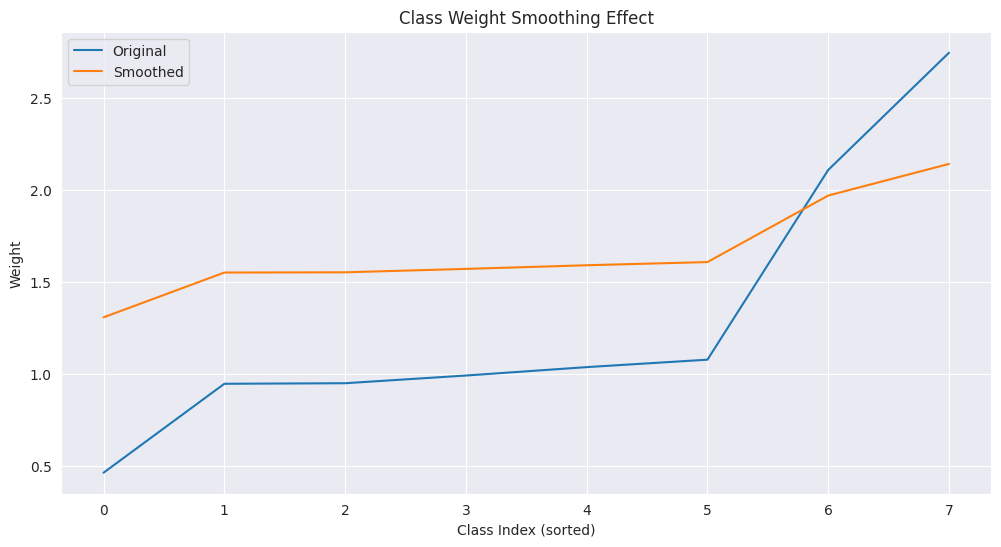

ℹ️ Using weight strategy: balanced


In [15]:
# Define weight strategy
WEIGHT_STRATEGY, weight_values = check_weight_strategy(
    labels=tokenized_dataset["train"]["label"],
    threshold=10.0,
    visualize=True
)
print(f"ℹ️ Using weight strategy: {WEIGHT_STRATEGY}")

In [16]:
# Set config
model_config = AutoConfig.from_pretrained(
    config.model.base_model,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

# Initialize model
model = AutoModelForSequenceClassification.from_pretrained(
    config.model.base_model,
    config=model_config,
    device_map='auto'
).to(DEVICE)

# Define early stopping strategy
early_stopping = EarlyStoppingCallback(
    early_stopping_patience=2,
    early_stopping_threshold=0.005,
)

# LoRA setup
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    init_lora_weights="gaussian",
    lora_dropout=0.1,
    target_modules="all-linear"
    # target_modules=["query", "key", "value", "dense"]
)
model = get_peft_model(model, peft_config)
model.print_trainable_parameters()

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 4,596,744 || all params: 359,964,688 || trainable%: 1.2770


### Metrics

In [17]:
def compute_metrics(eval_pred, average="weighted"):

    accuracy_metric = evaluate.load("accuracy")
    recall_metric = evaluate.load("recall")
    precision_metric = evaluate.load("precision")
    f1_metric = evaluate.load("f1")

    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"],
        "recall": recall_metric.compute(predictions=predictions, references=labels, average=average)["recall"],
        "precision": precision_metric.compute(predictions=predictions, references=labels, average=average)["precision"],
        "f1": f1_metric.compute(predictions=predictions, references=labels, average=average)["f1"]
    }

### Train

In [ ]:
training_args = TrainingArguments(
    output_dir=f"./results/{FINETUNED_MODEL_NAME}" if SAVE_LOCAL else None,
    # logs_dir=f"./logs/{FINETUNED_MODEL_NAME}",
    num_train_epochs=8,
    bf16=torch.cuda.is_bf16_supported(),
    fp16=not torch.cuda.is_bf16_supported(),
    per_device_train_batch_size=2,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    eval_accumulation_steps=4,
    weight_decay=0.01,
    warmup_steps=20,
    lr_scheduler_type='linear',
    seed=config.env.seed,

    eval_strategy ="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,

    logging_strategy="epoch",
    report_to = config.tracking.tracker,
    run_name = f"{config.tracking.project}/{FINETUNED_MODEL_NAME}",
    project = config.tracking.project,
    trackio_space_id  = config.tracking.trackio_space_id,
    push_to_hub = False, # False: push only the best model (after training completion)
    hub_private_repo = False,
    hub_model_id = FINETUNED_MODEL_NAME,
)

trainer = WeightedLossTrainer(
    model=model,
    class_weights=weight_values,
    args=training_args,
    train_dataset=tokenized_dataset["train"] if not SMOKE_TEST else sampled_dataset["train"],
    eval_dataset=tokenized_dataset["valid"] if not SMOKE_TEST else sampled_dataset["valid"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    callbacks=[early_stopping]
)

* Run finished. Uploading logs to the remote Trackio server (please wait...)
* Created new run: Francesco-A-1780154104


In [26]:
if not VALIDATION_ONLY:
    history = trainer.train(resume_from_checkpoint=False)
    if PUSH_TO_HUB:
        trainer.push_to_hub(commit_message="Upload adapter weights and tokenizer")
        trainer.model.config.push_to_hub(
            commit_message="Pushing configs (with label mappings)",
            repo_id=trainer.args.hub_model_id
        )

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   3%|2         |  547kB / 18.4MB            

  ...RA-v1.1/training_args.bin:   3%|2         |   160B / 5.39kB            

README.md:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

```markdown
Epoch	Training Loss	Validation Loss	Accuracy	Recall	Precision	F1
1	4.796509	0.815203	0.725780	0.725780	0.737214	0.724300
2	2.887393	0.863184	0.729064	0.729064	0.741933	0.726515
3	2.182435	0.851537	0.742200	0.742200	0.749447	0.741744
4	1.676231	0.809233	0.765189	0.765189	0.774387	0.766757
5	1.227654	0.972264	0.747126	0.747126	0.749622	0.746471
6	0.915558	1.036352	0.763547	0.763547	0.764963	0.763767
```

## Model evaluation

In [33]:
# Download the trained model or use the model from training
DOWNLOAD_INFERENCE_MODEL = True

if VALIDATION_ONLY and DOWNLOAD_INFERENCE_MODEL:
    model_path = f"Francesco-A/{config.model.finetuned_model}"
    # Load the fine-tuned model and tokenizer from Hugging Face Hub
    inference_model = AutoModelForSequenceClassification.from_pretrained(
        model_path,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id
    ).to(DEVICE)
    inference_model.eval()
    inference_tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name_or_path=model_path)
else:
    # Use the model and tokenizer from the training session (already in memory)
    inference_model = trainer.model
    inference_model.eval()

In [37]:
# Create a Trainer instance for inference (no training, just to use the predict method)
inference_trainer = WeightedLossTrainer(
    model=inference_model,
    class_weights=weight_values,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Evaluate on the test set
eval_results = inference_trainer.evaluate(tokenized_dataset["test"])
print("Test set evaluation results:")
pprint(eval_results)

Test set evaluation results:
{'eval_accuracy': 0.7475409836065574,
 'eval_f1': 0.7482905495108884,
 'eval_loss': 0.8260096311569214,
 'eval_model_preparation_time': 0.0184,
 'eval_precision': 0.753472589548565,
 'eval_recall': 0.7475409836065574,
 'eval_runtime': 33.1303,
 'eval_samples_per_second': 18.412,
 'eval_steps_per_second': 2.324}


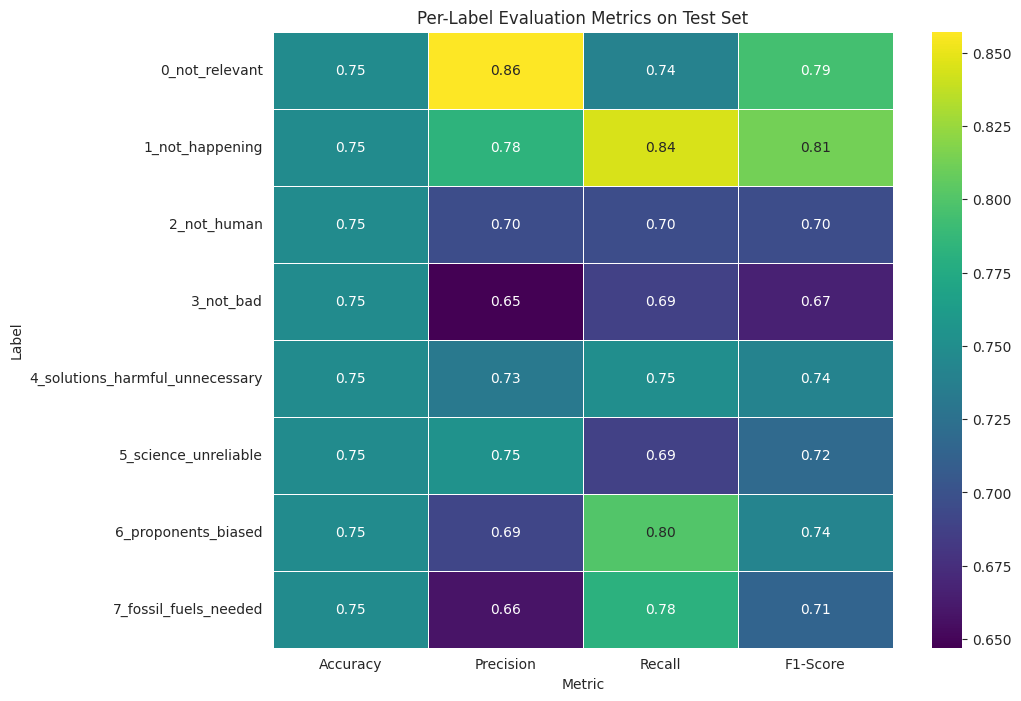

In [ ]:
# Check per-label performance and visualize with heatmap
predictions, label_ids, _ = inference_trainer.predict(tokenized_dataset["test"])

# Get per-label metrics without averaging
metrics = compute_metrics((predictions, label_ids), average=None)

# Create a DataFrame for heatmap
metrics_df = pd.DataFrame({
    'Accuracy': metrics["accuracy"],
    'Precision': metrics["precision"],
    'Recall': metrics["recall"],
    'F1-Score': metrics["f1"]
}, index=label2id.keys())

metrics_df = metrics_df.fillna(0)

# Save metrics table
metrics_df.to_csv("evals/tables/label_metrics.csv", index=True)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(metrics_df, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Per-Label Evaluation Metrics on Test Set')
plt.ylabel('Label')
plt.xlabel('Metric')
plt.savefig("evals/images/label_metrics_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

## Requirements (full snapshot)

In [84]:
!pip freeze > snapshots/01_train_eval.txt